#  Exploratory Data Analysis — Retail Demand Forecasting

**Business problem:** a retailer with 5 stores and 20 products needs to know how many units customers will want each day, so it can avoid both **stockouts** (lost sales) and **overstock** (tied-up capital).

### Questions this notebook answers
1. Is the data clean and structurally consistent (one row per store × product × day)?
2. What drives demand: category, store, price, promotions, seasonality, weather?
3. What time-series patterns exist (trend, weekly/yearly seasonality, autocorrelation)?
4. How much demand is lost to stockouts — and where?
5. What do these findings imply for feature engineering and validation?


##  Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 5), "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

# Paths are relative to the project root, so the notebook runs on any machine
ROOT = Path("..")
RAW_PATH = ROOT / "data" / "raw" / "demand_forecasting.csv"
PROCESSED_PATH = ROOT / "data" / "processed" / "demand_clean.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)


def save_fig(name: str) -> None:
    """Save the current figure to reports/figures (used later in the README)."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Load data & first look

In [2]:
df = pd.read_csv(RAW_PATH, parse_dates=["Date"])
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

print(f"Shape      : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Date range : {df['date'].min().date()} → {df['date'].max().date()}  ({df['date'].nunique()} days)")
df.head()

Shape      : 76,000 rows × 16 columns
Date range : 2022-01-01 → 2024-01-30  (760 days)


,date,store_id,product_id,category,region,inventory_level,units_sold,units_ordered,price,discount,weather_condition,promotion,competitor_pricing,seasonality,epidemic,demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                76000 non-null  datetime64[us]
 1   store_id            76000 non-null  str           
 2   product_id          76000 non-null  str           
 3   category            76000 non-null  str           
 4   region              76000 non-null  str           
 5   inventory_level     76000 non-null  int64         
 6   units_sold          76000 non-null  int64         
 7   units_ordered       76000 non-null  int64         
 8   price               76000 non-null  float64       
 9   discount            76000 non-null  int64         
 10  weather_condition   76000 non-null  str           
 11  promotion           76000 non-null  int64         
 12  competitor_pricing  76000 non-null  float64       
 13  seasonality         76000 non-null  str           
 14  e

###  Panel structure

In [4]:
KEYS = ["store_id", "product_id"]
series_sizes = df.groupby(KEYS).size()
all_days = pd.date_range(df["date"].min(), df["date"].max(), freq="D")

print(f"Number of time series      : {len(series_sizes)}")
print(f"Rows per series (min/max)  : {series_sizes.min()} / {series_sizes.max()}")
print(f"Calendar days missing      : {len(all_days.difference(df['date'].unique()))}")

Number of time series      : 100
Rows per series (min/max)  : 760 / 760
Calendar days missing      : 0


##  Data quality checks

In [5]:
checks = {
    "missing values": int(df.isna().sum().sum()),
    "duplicate rows": int(df.duplicated().sum()),
    "duplicate (date, store, product) keys": int(df.duplicated(["date", "store_id", "product_id"]).sum()),
    "negative numeric values": int((df.select_dtypes("number") < 0).sum().sum()),
    "units_sold > inventory_level": int((df["units_sold"] > df["inventory_level"]).sum()),
    "units_sold > demand": int((df["units_sold"] > df["demand"]).sum()),
    "inventory_level == 0": int((df["inventory_level"] == 0).sum()),
}
quality = pd.Series(checks, name="count").to_frame()
quality["% of rows"] = quality["count"] / len(df) * 100
quality

,count,% of rows
missing values,0,0.00
duplicate rows,0,0.00
"duplicate (date, store, product) keys",0,0.00
negative numeric values,0,0.00
units_sold > inventory_level,0,0.00
units_sold > demand,21000,27.63
inventory_level == 0,406,0.53


In [6]:
# Hierarchy consistency: does each product have ONE category, and each store ONE region?
print("Categories per product:", df.groupby("product_id")["category"].nunique().value_counts().to_dict())
print("Regions per store     :", df.groupby("store_id")["region"].nunique().value_counts().to_dict())

# Is the 'seasonality' label consistent with the calendar month?
pd.crosstab(df["date"].dt.month, df["seasonality"])

# Is the category constant inside each (store, product) series?
print("Max categories within one (store, product) series:", df.groupby(KEYS)["category"].nunique().max())

Categories per product: {3: 8, 4: 5, 2: 5, 5: 2}
Regions per store     : {1: 5}
Max categories within one (store, product) series: 1


In [7]:
# Outlier scan with the IQR rule (reported, NOT removed automatically)
num_cols = ["inventory_level", "units_sold", "units_ordered", "price", "competitor_pricing", "demand"]


def iqr_outlier_pct(s: pd.Series) -> float:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100


outliers = pd.DataFrame({
    "outliers_%": {c: iqr_outlier_pct(df[c]) for c in num_cols},
    "p50": df[num_cols].median(),
    "p99": df[num_cols].quantile(0.99),
    "max": df[num_cols].max(),
})
outliers

,outliers_%,p50,p99,max
inventory_level,3.63,227.00,"1,055.02","2,267.00"
units_sold,1.86,84.00,218.00,426.00
units_ordered,9.90,0.00,728.00,"1,616.00"
price,0.09,64.50,166.88,228.03
competitor_pricing,0.24,65.70,174.83,261.22
demand,1.30,100.00,234.00,430.00


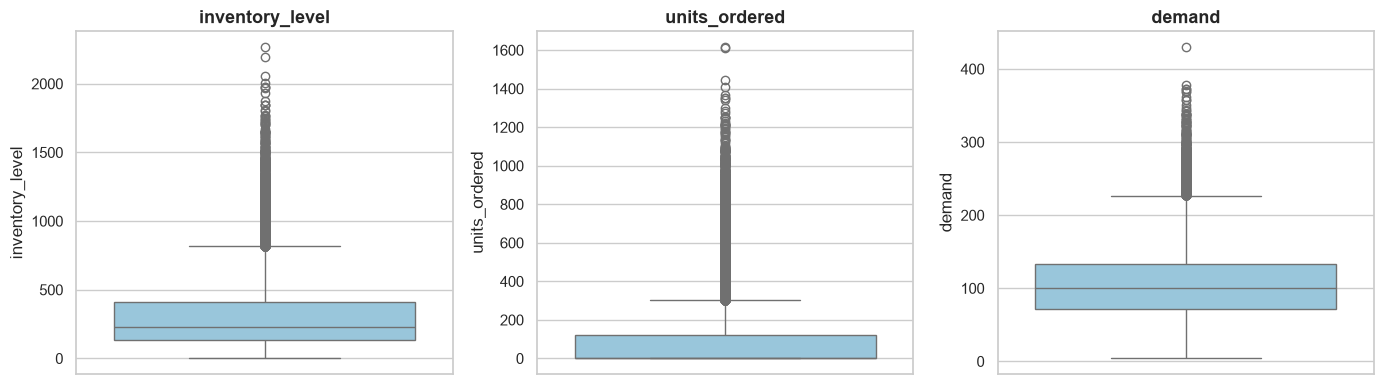

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["inventory_level", "units_ordered", "demand"]):
    sns.boxplot(y=df[col], ax=ax, color="#8ecae6")
    ax.set_title(col)
save_fig("01_outliers_boxplots")
plt.show()

### Findings — Data Quality

- **The panel is complete:** 100 series (5 stores × 20 products) × 760 days — exactly 760 rows per series, no missing days, no missing values, no duplicate rows or duplicate keys.
- **Business logic:** `units_sold` never exceeds `inventory_level` (0 violations), but it **does exceed `demand` in 27.6% of rows**. So `demand` is *not* simply "units sold + lost sales". I use `demand` as the target exactly as the dataset defines it, and I avoid calling it "true customer demand".
- **Identifiers:** a `product_id` does not map to one category (each product appears under 2–5 different categories across stores), so `product_id` alone is not a meaningful product identity. The unit of analysis is the **`(store_id, product_id)` series**; a `series_id` is created in Section 4.
- **Zeros and outliers:** `units_ordered` has a median of 0 (orders are placed only on some days); 406 rows (0.5%) have zero inventory; `inventory_level` has a long right tail (p99 ≈ 1,055, max 2,267).
- **Decision:** outliers are kept. They are plausible (stock deliveries, demand spikes) and tree-based models are robust to them.

##  Feature engineering for analysis

In [9]:
# ── Safe features ────────────────────────────────────────────
df["series_id"] = df["store_id"] + "_" + df["product_id"]   # one id per time series
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["week"] = df["date"].dt.isocalendar().week.astype(int)
df["dayofweek"] = df["date"].dt.dayofweek          # Monday = 0
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

df["final_price"] = df["price"] * (1 - df["discount"] / 100)   # assumes `price` is the pre-discount price
df["price_vs_competitor"] = df["price"] / df["competitor_pricing"]

# ── Analysis-only features (use the outcome `units_sold`) ──────
df["unmet_demand"] = (df["demand"] - df["units_sold"]).clip(lower=0)
df["stockout"] = (df["units_sold"] >= df["inventory_level"]).astype(int)      # stock fully exhausted
df["sell_through_rate"] = np.where(df["inventory_level"] > 0,
                                   df["units_sold"] / df["inventory_level"] * 100, np.nan)

ANALYSIS_ONLY = ["unmet_demand", "stockout", "sell_through_rate"]
print("Rows with sell_through_rate = NaN (inventory_level == 0):", df["sell_through_rate"].isna().sum())
df[["date", "demand", "units_sold", "inventory_level", "unmet_demand", "stockout", "final_price"]].head()

Rows with sell_through_rate = NaN (inventory_level == 0): 406


,date,demand,units_sold,inventory_level,unmet_demand,stockout,final_price
0,2022-01-01,115,102,195,13,0,69.08
1,2022-01-01,229,117,117,112,1,68.14
2,2022-01-01,157,114,247,43,0,56.65
3,2022-01-01,52,45,139,7,0,78.87
4,2022-01-01,59,65,152,0,0,54.41


> **Note on `sell_through_rate`:** when `inventory_level = 0` the ratio is undefined, so it is set to `NaN` explicitly instead of letting a division-by-zero slip through silently.

##  The target variable: `demand`

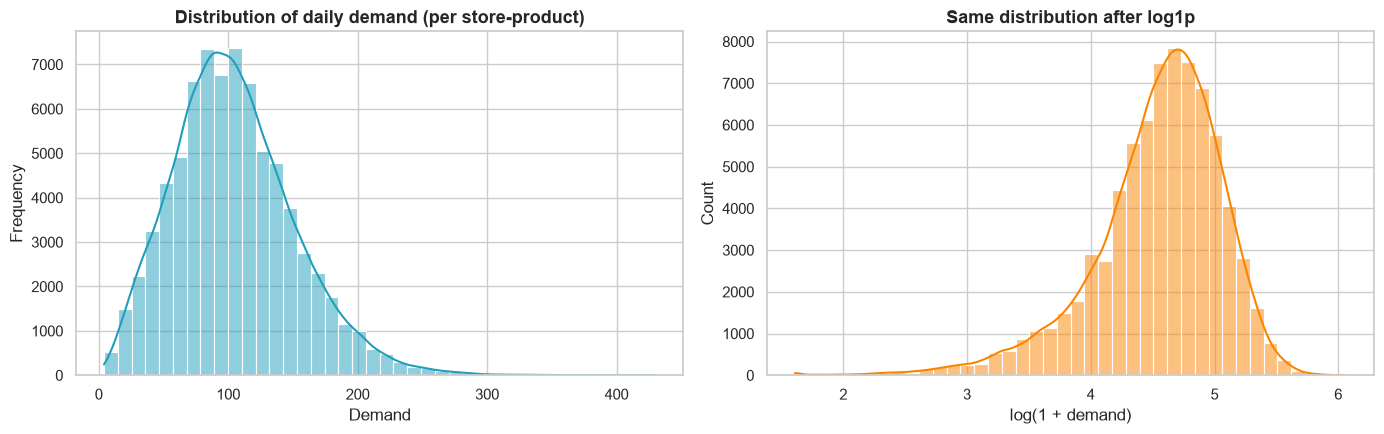

Mean 104.3 | Median 100.0 | Std 47.0 | Skew 0.61 | Min 4 | Max 430


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df["demand"], bins=40, kde=True, ax=axes[0], color="#219ebc")
axes[0].set(title="Distribution of daily demand (per store-product)", xlabel="Demand", ylabel="Frequency")
sns.histplot(np.log1p(df["demand"]), bins=40, kde=True, ax=axes[1], color="#fb8500")
axes[1].set(title="Same distribution after log1p", xlabel="log(1 + demand)")
save_fig("02_demand_distribution")
plt.show()

print(f"Mean {df['demand'].mean():.1f} | Median {df['demand'].median():.1f} | Std {df['demand'].std():.1f} | Skew {df['demand'].skew():.2f} | Min {df['demand'].min()} | Max {df['demand'].max()}")

**Finding:** mean 104.3, median 100.0, std 47.0, skew 0.61 → demand is only *mildly* right-skewed, so a log-transform is unlikely to be necessary. **WAPE / MAE** will be the primary metrics; MAPE is only safe if the minimum demand is far from zero (see `Min` printed above).

## What drives demand?

In [11]:
def demand_by(cols, ncols=3, order_by_mean=True):
    """Print summary tables and plot mean demand (±2 SE) for each column in `cols`."""
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
    for ax, col in zip(axes.ravel(), cols):
        summary = df.groupby(col)["demand"].agg(["count", "mean", "median", "std"])
        order = summary.sort_values("mean", ascending=False).index if order_by_mean else summary.index
        sns.barplot(data=df, x=col, y="demand", order=order, errorbar=("se", 2), color="#8ecae6", ax=ax)
        ax.set_title(f"Mean demand by {col}")
        ax.tick_params(axis="x", rotation=30)
        display(summary.loc[order].round(1))
    for ax in axes.ravel()[len(cols):]:
        ax.set_visible(False)
    return fig

### Product & location

,count,mean,median,std
category,,,,
Groceries,30400,121.00,116.00,48.40
Clothing,12160,112.60,109.00,41.00
Electronics,9120,97.50,95.00,40.60
Toys,10640,92.60,92.00,46.20
Furniture,13680,73.60,72.00,32.30


,count,mean,median,std
store_id,,,,
S002,15200,106.90,103.00,45.60
S003,15200,106.50,102.00,47.40
S005,15200,105.70,102.00,48.30
S001,15200,101.80,98.00,47.10
S004,15200,100.60,96.00,46.00


,count,mean,median,std
region,,,,
South,15200,106.90,103.00,45.60
East,15200,106.50,102.00,47.40
North,30400,103.80,100.00,47.70
West,15200,100.60,96.00,46.00


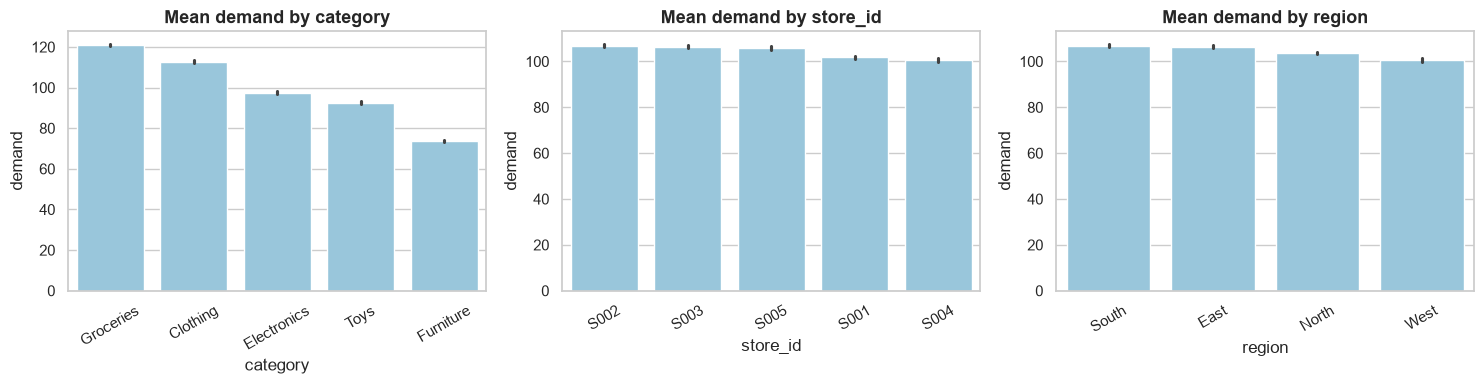

In [12]:
demand_by(["category", "store_id", "region"])
save_fig("03_demand_by_product_location")
plt.show()

### 6.2 External context

,count,mean,median,std
weather_condition,,,,
Sunny,22980,115.20,111.00,51.10
Cloudy,24360,105.40,102.00,46.60
Rainy,17500,95.10,92.00,42.60
Snowy,11160,94.00,91.00,39.50


,count,mean,median,std
seasonality,,,,
Summer,18400,112.90,107.00,51.90
Autumn,18200,103.40,100.00,42.00
Winter,21000,103.40,100.00,46.20
Spring,18400,97.70,95.00,46.00


,count,mean,median,std
epidemic,,,,
0,60800,112.90,108.00,44.60
1,15200,70.20,64.00,40.00


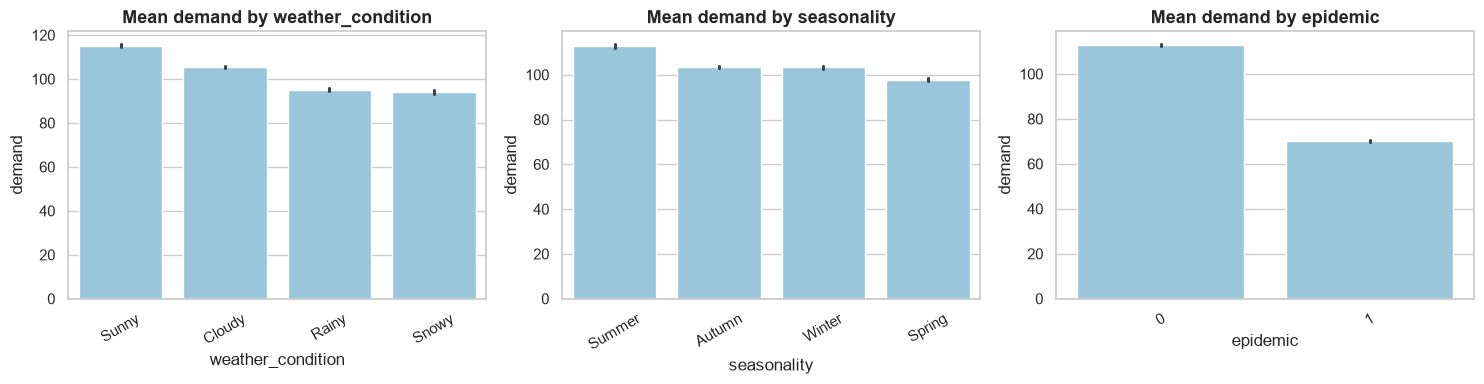

In [13]:
demand_by(["weather_condition", "seasonality", "epidemic"])
save_fig("04_demand_by_context")
plt.show()

###  Pricing & marketing

,count,mean,median,std
promotion,,,,
0,51000,95.00,92.00,40.70
1,25000,123.30,120.00,52.90


,count,mean,median,std
discount,,,,
0,17126,94.70,92.00,40.50
5,16918,94.90,92.00,40.80
10,23298,102.80,99.00,46.00
15,6245,123.60,120.00,53.10
20,6191,124.10,120.00,53.00
25,6222,123.00,120.00,52.60


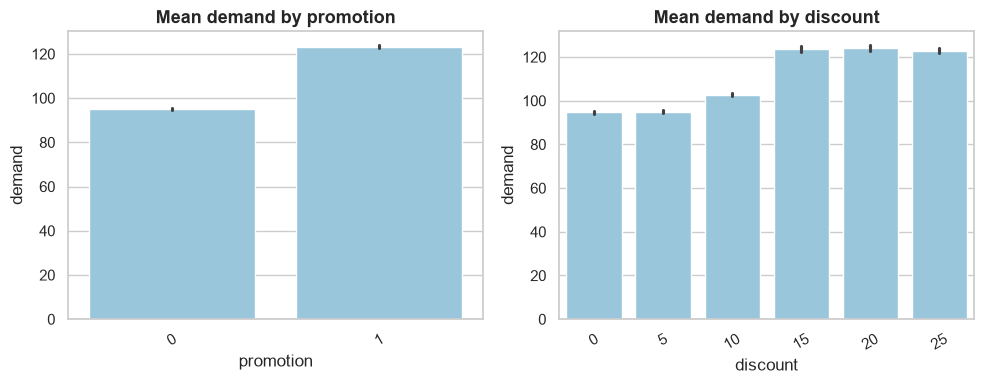

In [14]:
demand_by(["promotion", "discount"], ncols=2, order_by_mean=False)
save_fig("05_demand_by_pricing")
plt.show()

#### Is the promotion effect real, or a side-effect of the product mix?
The raw gap (Promotion = 1 → mean demand ≈ **123.3** vs. ≈ **95.0** without promotion, i.e. **≈ +30%**) looks large. But if promotions happen mostly on high-demand categories, the gap would be **confounded**. Checking the uplift *within* each category:

In [15]:
promo = df.pivot_table(values="demand", index="category", columns="promotion", aggfunc="mean")
promo.columns = ["no_promo", "promo"]
promo["uplift_%"] = (promo["promo"] / promo["no_promo"] - 1) * 100
promo["promo_share_%"] = df.groupby("category")["promotion"].mean() * 100
promo.round(1)

,no_promo,promo,uplift_%,promo_share_%
category,,,,
Clothing,102.70,132.80,29.30,32.90
Electronics,88.60,115.60,30.60,32.90
Furniture,66.90,87.30,30.50,32.90
Groceries,110.30,142.80,29.40,32.90
Toys,84.30,109.50,29.80,32.90


**Finding:** the promotion uplift is **29–31% in every category** (Clothing +29.3%, Electronics +30.6%, Furniture +30.5%, Groceries +29.4%, Toys +29.8%), and every category has the same promoted share (32.9%). The overall ≈ +30% gap is therefore *not* an artefact of the product mix.

> **Caution:** this is an *association*, not proof of causality. In the report I say "promotion days are associated with higher demand", never "promotion causes +30%".

#### Promotion vs. discount
Mean demand by discount level is a **step**, not a slope: ≈ 94.7–94.9 at 0–5%, 102.8 at 10%, and ≈ 123–124 at 15%, 20% and 25% — the same level as promoted days (123.3). More discount beyond 15% adds nothing. Let's check how much `promotion` and `discount` overlap:

In [16]:

print("Share of promoted rows within each discount level (%):")
display((pd.crosstab(df["discount"], df["promotion"], normalize="index") * 100).round(1))

print("Mean demand by discount × promotion:")
display(df.pivot_table(values="demand", index="discount", columns="promotion", aggfunc="mean").round(1))


Share of promoted rows within each discount level (%):


promotion,0,1
discount,,
0,100.00,0.00
5,100.00,0.00
10,72.80,27.20
15,0.00,100.00
20,0.00,100.00
25,0.00,100.00


Mean demand by discount × promotion:


promotion,0,1
discount,,
0,94.70,NaN
5,94.90,NaN
10,95.40,122.50
15,NaN,123.60
20,NaN,124.10
25,NaN,123.00


### 6.4 Price vs. demand

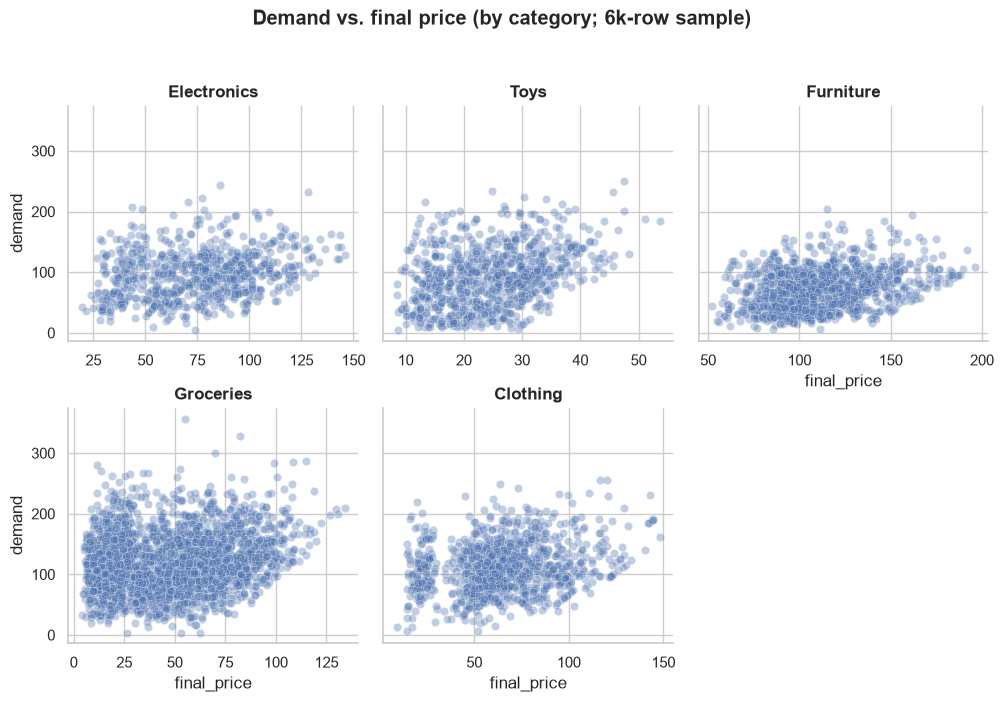

In [17]:
sample = df.sample(6000, random_state=42)
g = sns.relplot(data=sample, x="final_price", y="demand", col="category", col_wrap=3,
                alpha=0.35, height=3.4, facet_kws={"sharex": False})
g.set_titles("{col_name}")
g.figure.suptitle("Demand vs. final price (by category; 6k-row sample)", y=1.03, fontweight="bold")
save_fig("06_price_vs_demand")
plt.show()

Prices live on very different scales per category, so a single global scatter plot (as in a first attempt) hides the relationship — faceting by category fixes that.

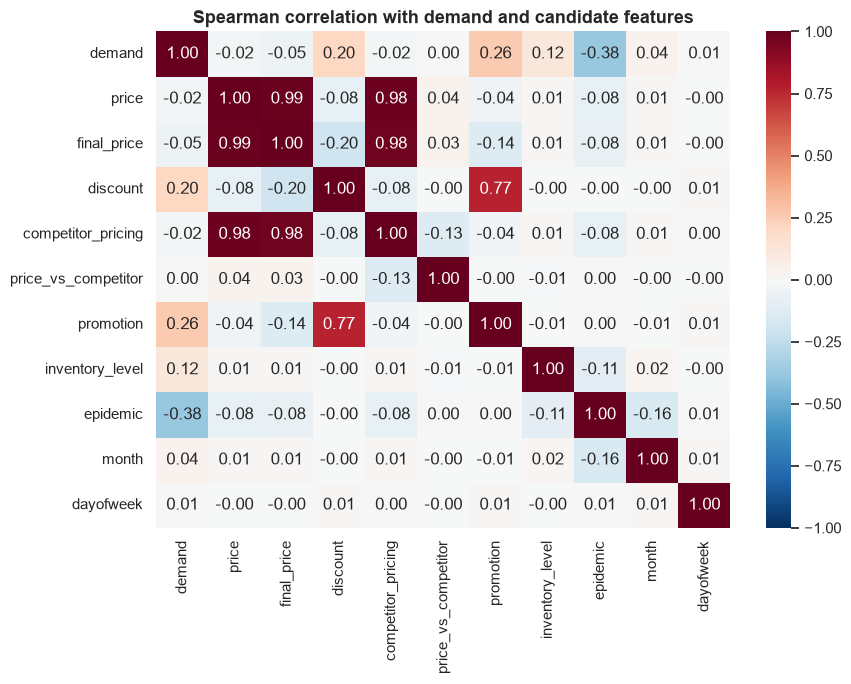

In [18]:
corr_cols = ["demand", "price", "final_price", "discount", "competitor_pricing", "price_vs_competitor",
             "promotion", "inventory_level", "epidemic", "month", "dayofweek"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation with demand and candidate features")
save_fig("07_correlation_heatmap")
plt.show()


### The epidemic flag — a regime, not just a feature
The aggregated daily series (Section 7) shows abrupt drops. Do they coincide with `epidemic = 1`? Is the flag global (same for all series on a given day)? How many separate episodes are there, and is the drop similar across categories?


In [19]:

epi_day = df.groupby("date")["epidemic"].agg(["min", "max"])
print("Epidemic flag identical for all series on each day:", bool((epi_day["min"] == epi_day["max"]).all()))

flag = epi_day["max"].astype(int)
block = (flag != flag.shift()).cumsum()
on = flag == 1
episodes = (flag[on].reset_index().assign(block=block[on].values)
            .groupby("block")["date"].agg(start="min", end="max", days="count"))
print(f"{len(episodes)} episodes | {int(flag.sum())} epidemic days ({flag.mean() * 100:.0f}% of all days)")
episodes


Epidemic flag identical for all series on each day: True
6 episodes | 152 epidemic days (20% of all days)


,start,end,days
block,,,
2,2022-04-23,2022-05-25,33
4,2022-06-29,2022-07-24,26
6,2023-01-29,2023-02-28,31
8,2023-04-12,2023-05-12,31
10,2023-10-07,2023-10-24,18
12,2023-12-27,2024-01-08,13


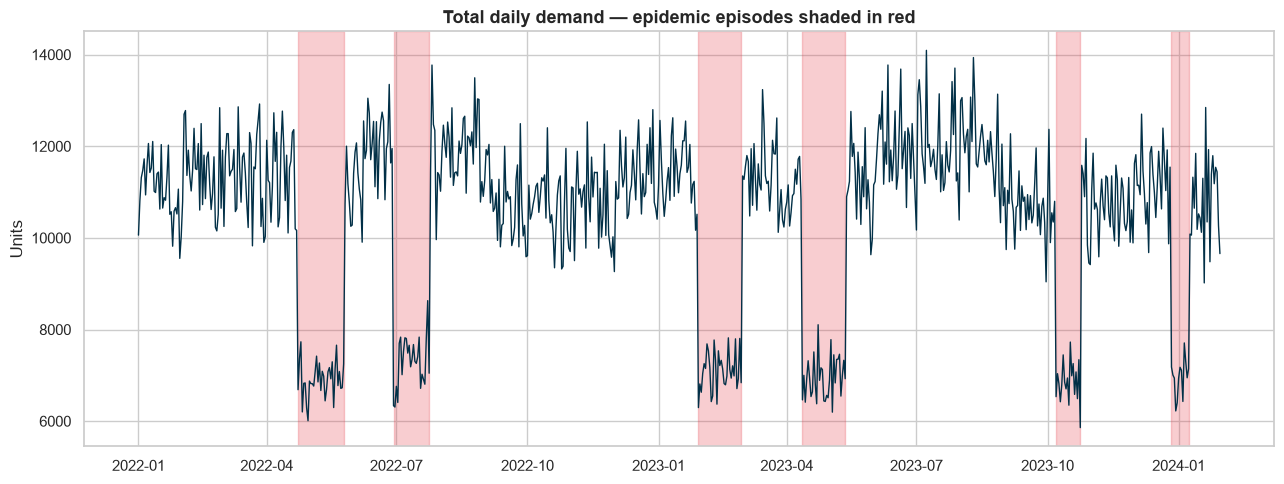

,normal,epidemic,change_%
category,,,
Clothing,112.30,113.70,1.30
Electronics,107.30,58.10,-45.80
Furniture,82.60,37.50,-54.70
Groceries,130.20,83.90,-35.60
Toys,107.40,33.50,-68.80


In [20]:

daily_total = df.groupby("date")["demand"].sum()
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(daily_total.index, daily_total, color="#023047", linewidth=1)
for _, r in episodes.iterrows():
    ax.axvspan(r["start"], r["end"], color="#e63946", alpha=0.25)
ax.set(title="Total daily demand — epidemic episodes shaded in red", ylabel="Units")
save_fig("08b_epidemic_episodes")
plt.show()

drop = df.pivot_table(values="demand", index="category", columns="epidemic", aggfunc="mean")
drop.columns = ["normal", "epidemic"]
drop["change_%"] = (drop["epidemic"] / drop["normal"] - 1) * 100
drop.round(1)


## 7. Time-series analysis
This is the part that makes the project a *forecasting* project. Questions: is there a **trend**, **weekly seasonality**, **yearly seasonality**, and how strongly does today's demand depend on past demand?

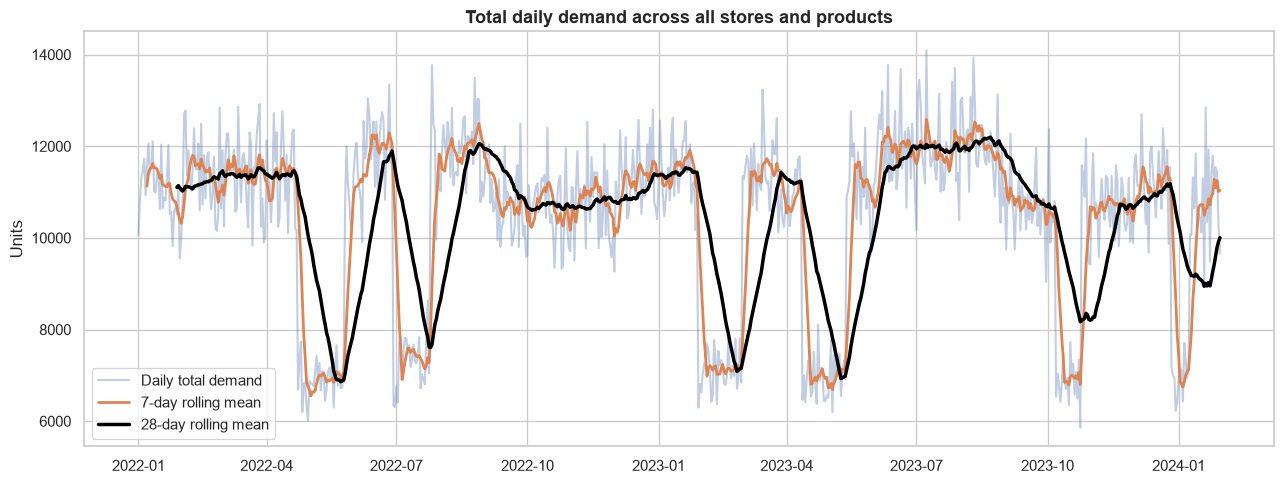

In [21]:
daily = df.groupby("date")["demand"].sum().asfreq("D")
assert daily.isna().sum() == 0, "Missing days in the aggregated series"

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(daily.index, daily, alpha=0.35, label="Daily total demand")
ax.plot(daily.index, daily.rolling(7).mean(), label="7-day rolling mean", linewidth=2)
ax.plot(daily.index, daily.rolling(28).mean(), label="28-day rolling mean", linewidth=2.5, color="black")
ax.set(title="Total daily demand across all stores and products", xlabel="", ylabel="Units")
ax.legend()
save_fig("08_daily_total_demand")
plt.show()

### 7.1 Yearly seasonality — each year as its own line

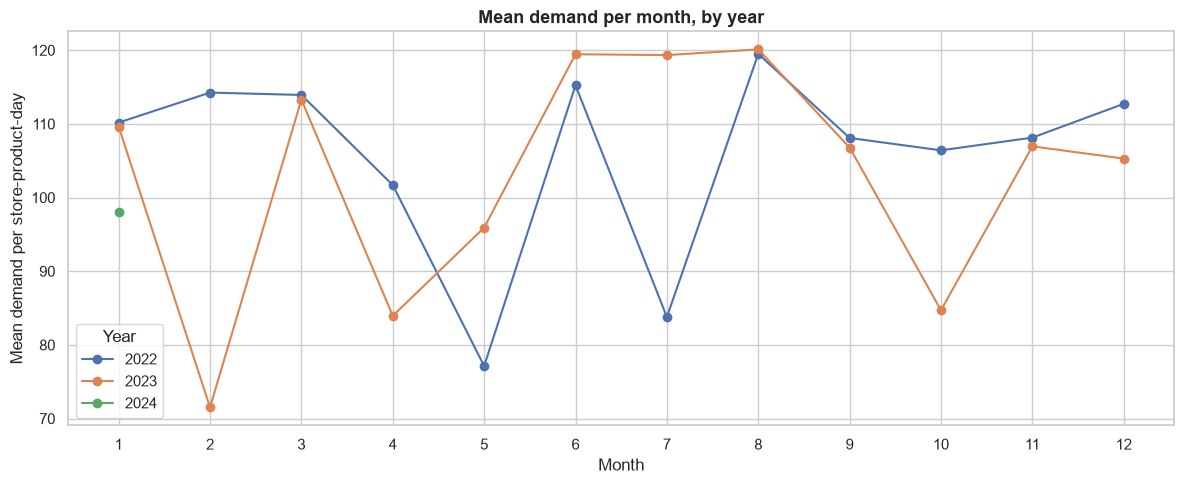

In [22]:
monthly = df.groupby(["year", "month"])["demand"].mean().unstack(0)
ax = monthly.plot(marker="o", figsize=(12, 5))
ax.set(title="Mean demand per month, by year", xlabel="Month", ylabel="Mean demand per store-product-day")
ax.set_xticks(range(1, 13))
plt.legend(title="Year")
save_fig("09_yearly_seasonality")
plt.show()

*Note: 2024 contains only January, so it appears as a single point.*

### 7.2 Category × month seasonal index

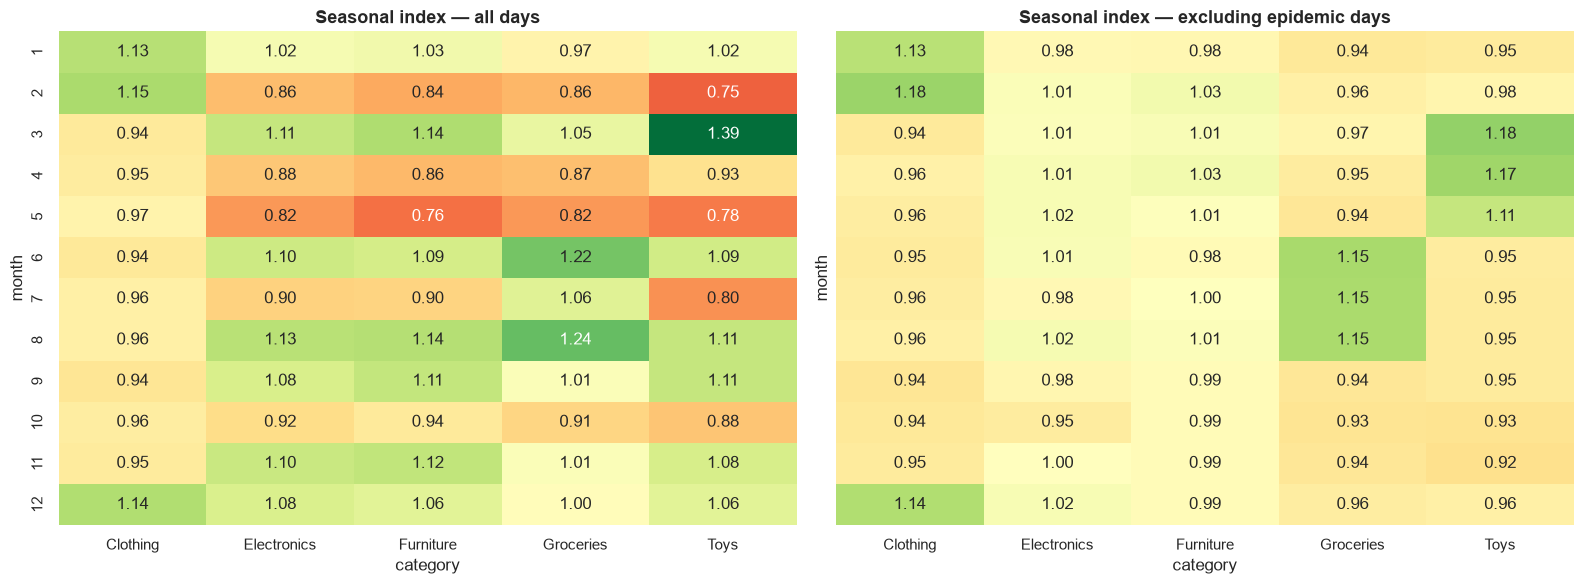

In [23]:
def seasonal_index(data):
    s = data.pivot_table(values="demand", index="month", columns="category", aggfunc="mean")
    return s / s.mean()          # 1.0 = the category's own average


fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
panels = [("all days", df), ("excluding epidemic days", df[df["epidemic"] == 0])]
for ax, (title, data) in zip(axes, panels):
    sns.heatmap(seasonal_index(data), annot=True, fmt=".2f", cmap="RdYlGn", center=1.0,
                vmin=0.7, vmax=1.4, cbar=False, ax=ax)
    ax.set_title(f"Seasonal index — {title}")
save_fig("10_seasonal_index_heatmap")
plt.show()

### 7.3 Weekly seasonality

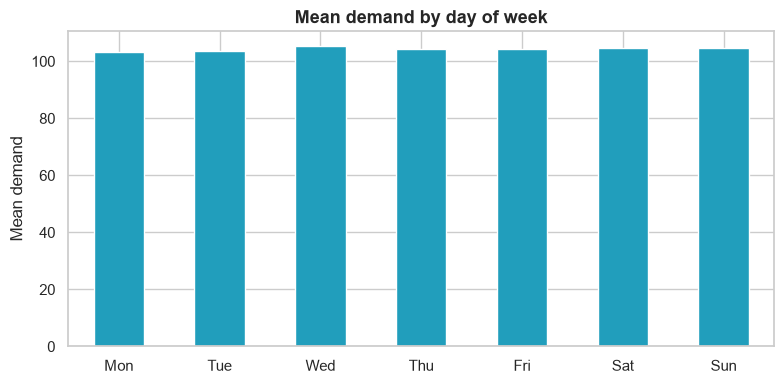

In [24]:
dow = df.groupby("dayofweek")["demand"].mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
ax = dow.plot(kind="bar", color="#219ebc", figsize=(8, 4))
ax.set(title="Mean demand by day of week", xlabel="", ylabel="Mean demand")
plt.xticks(rotation=0)
save_fig("11_day_of_week")
plt.show()


**Finding:** the weekday profile is almost flat (103.4 on Monday vs. 105.2 on Wednesday — under a 2% spread). `dayofweek` is a cheap feature, but no strong weekly cycle should be expected.


### 7.4 Trend / seasonality / residual decomposition (STL)

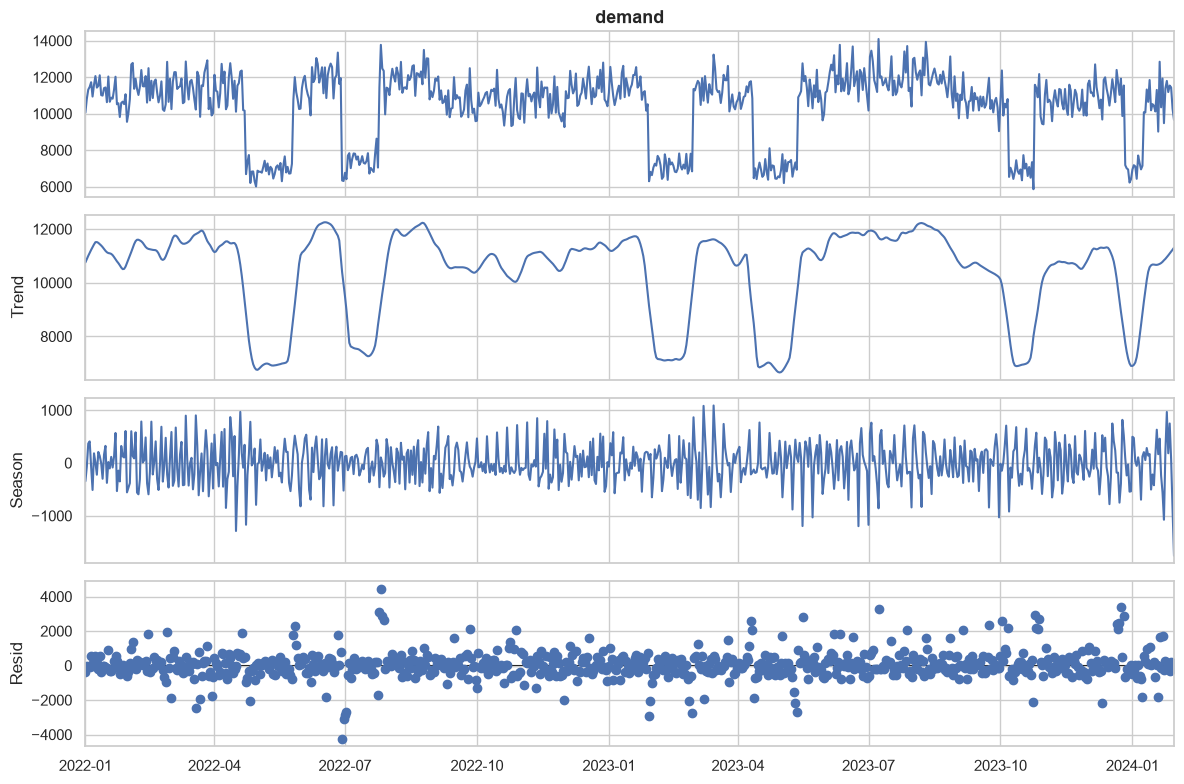

Weekly-seasonality strength: 0.16   |   Trend strength: 0.81   (0 = none, 1 = very strong)


In [25]:
stl = STL(daily, period=7, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(12, 8)
save_fig("12_stl_decomposition")
plt.show()

strength_seasonal = max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())
strength_trend = max(0, 1 - stl.resid.var() / (stl.resid + stl.trend).var())
print(f"Weekly-seasonality strength: {strength_seasonal:.2f}   |   Trend strength: {strength_trend:.2f}   (0 = none, 1 = very strong)")


**Reading the decomposition:** weekly-seasonality strength is only **0.16** (weak). The **0.81 "trend strength" is misleading**: the "trend" is mostly the epidemic regime switching on and off (sharp steps down and up), not a gradual long-term trend.


### 7.5 Autocorrelation — how far back should the model look?

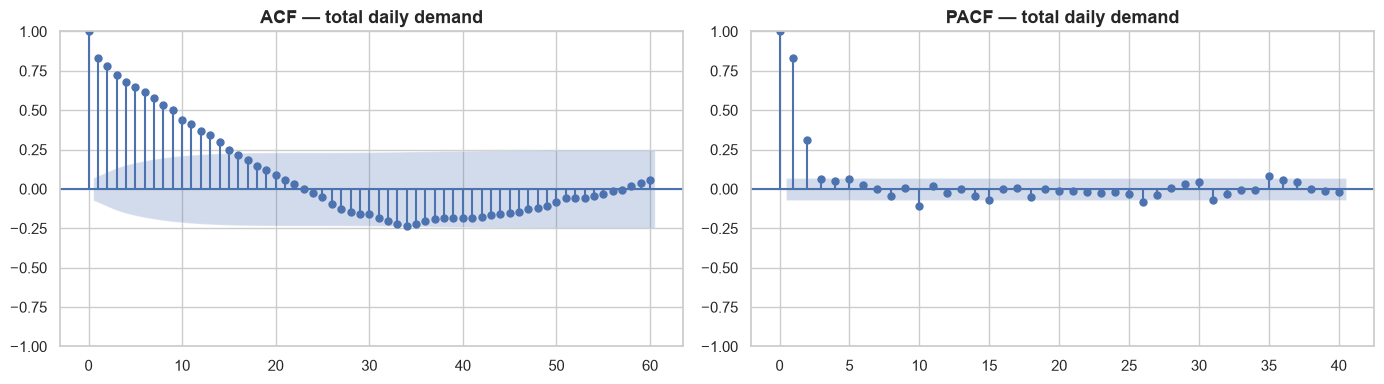

ADF test p-value = 0.0000  →  stationary at 5% level


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(daily, lags=60, ax=axes[0])
plot_pacf(daily, lags=40, ax=axes[1], method="ywm")
axes[0].set_title("ACF — total daily demand")
axes[1].set_title("PACF — total daily demand")
save_fig("13_acf_pacf")
plt.show()

with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)   # statsmodels announces a future change in adfuller's return type
    adf_stat, adf_p, *_ = adfuller(daily)
print(f"ADF test p-value = {adf_p:.4f}  →  {'stationary' if adf_p < 0.05 else 'NOT stationary (trend/seasonality present)'} at 5% level")

**How to read this:** the ACF decays *slowly and smoothly* (≈ 0.83 at lag 1, still ≈ 0.55 at lag 7, crossing zero around lag 22) with **no spikes at lags 7, 14, 21** → no weekly cycle, consistent with the flat day-of-week profile. The PACF is significant essentially at **lags 1–2 only**. The persistence comes from the *regime* (epidemic on/off), not from a calendar cycle.

The ADF test rejects a unit root (p < 0.001), but that does not mean there is nothing to model: the level jumps between two regimes.

**Implication:** lag features must respect the forecast horizon. For a 7-day-ahead forecast only lags ≥ 7 are allowed: `lag_7`, `lag_14`, `lag_28` and *shifted* rolling means are candidates, but they will react to a regime change with a delay. Using `lag_1` would only be legitimate for a 1-day-ahead forecast.

### 7.6 One real series: demand vs. what was actually sold

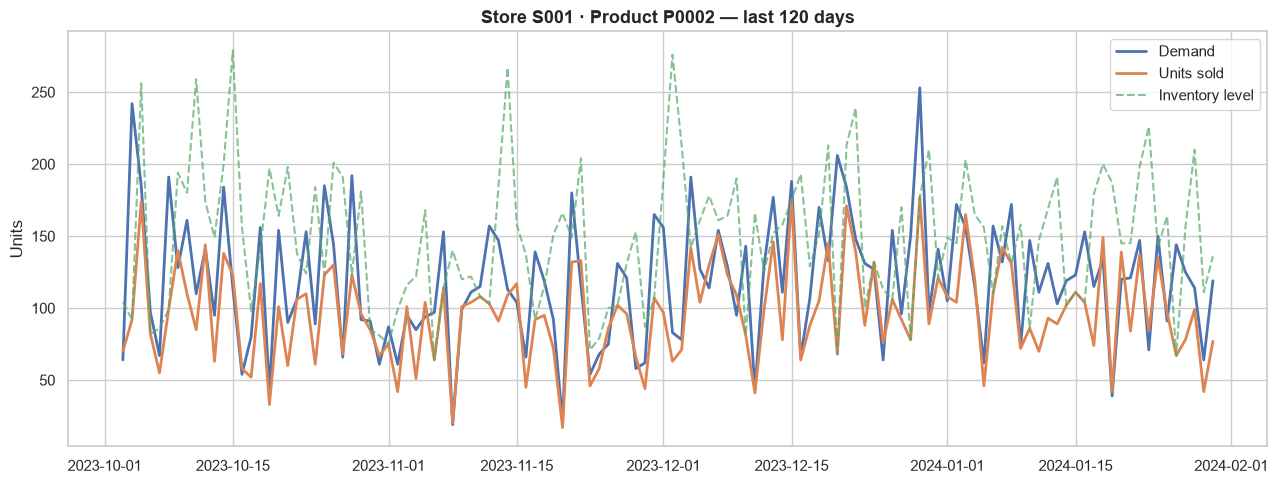

In [27]:
top = df.groupby(KEYS)["demand"].mean().idxmax()
one = df[(df["store_id"] == top[0]) & (df["product_id"] == top[1])].set_index("date").iloc[-120:]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(one.index, one["demand"], label="Demand", linewidth=2)
ax.plot(one.index, one["units_sold"], label="Units sold", linewidth=2)
ax.plot(one.index, one["inventory_level"], label="Inventory level", linestyle="--", alpha=0.7)
ax.set(title=f"Store {top[0]} · Product {top[1]} — last 120 days", ylabel="Units")
ax.legend()
save_fig("14_single_series_example")
plt.show()

##  Business insight: stockouts and unmet demand

In [28]:
stockout_rate = df["stockout"].mean() * 100
unmet_share = df["unmet_demand"].sum() / df["demand"].sum() * 100
print(f"Stockout days            : {stockout_rate:.1f}% of store-product-days")
print(f"Unmet demand             : {df['unmet_demand'].sum():,.0f} units  ({unmet_share:.1f}% of total demand)")

df.groupby("stockout")[["demand", "units_sold", "unmet_demand"]].mean().round(1).rename(index={0: "no stockout", 1: "stockout"})

Stockout days            : 11.4% of store-product-days
Unmet demand             : 1,388,383 units  (17.5% of total demand)


,demand,units_sold,unmet_demand
stockout,,,
no stockout,99.60,88.40,14.20
stockout,140.80,91.80,49.80


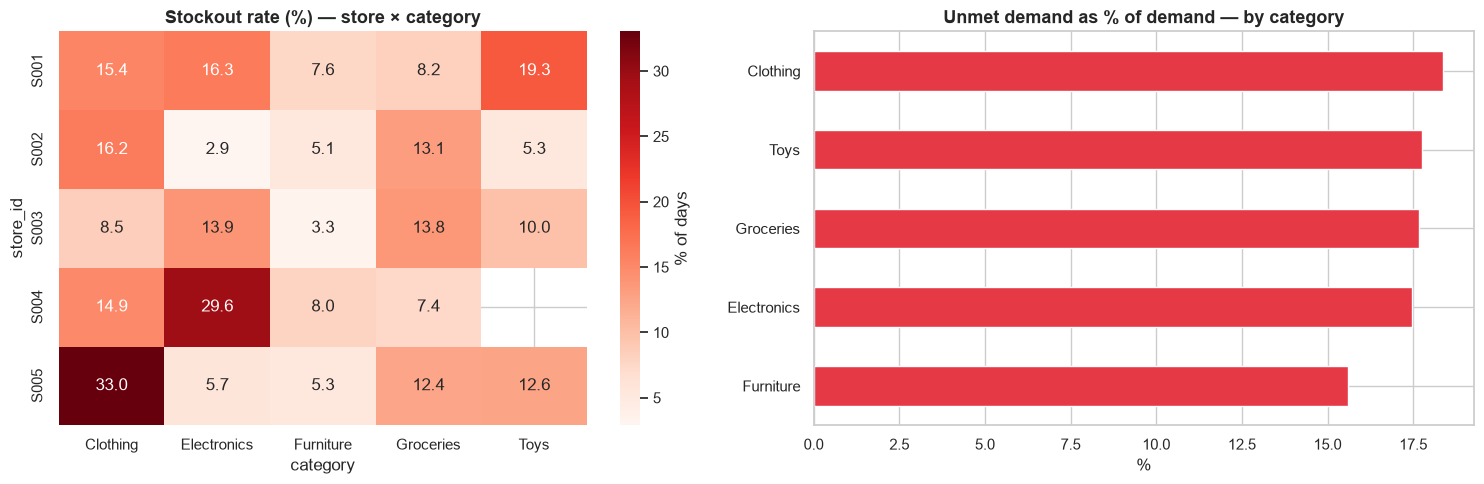

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

heat = df.pivot_table(values="stockout", index="store_id", columns="category", aggfunc="mean") * 100
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Reds", ax=axes[0], cbar_kws={"label": "% of days"})
axes[0].set_title("Stockout rate (%) — store × category")

unmet = (df.groupby("category")["unmet_demand"].sum() / df.groupby("category")["demand"].sum() * 100).sort_values()
unmet.plot(kind="barh", ax=axes[1], color="#e63946")
axes[1].set(title="Unmet demand as % of demand — by category", xlabel="%", ylabel="")
save_fig("15_stockouts")
plt.show()

**Finding — stockouts**

- **11.4%** of store-product-days end in a stockout, and **17.5%** of total demand (≈ 1.39M units) is unmet.
- Stockouts happen on **high-demand days**: mean demand is 140.8 on stockout days vs. 99.6 otherwise (unmet demand 49.8 vs. 14.2 units).
- **Hot spots:** S005 × Clothing (33.0%) and S004 × Electronics (29.6%), versus as low as 2.9% for S002 × Electronics — stock coverage varies strongly by store-category pair.
- Unmet demand as a share of demand is similar across categories (Furniture lowest ≈ 15.6%, Clothing highest ≈ 18.4%).

This turns the project from "predict a number" into "support an inventory decision": better forecasts should target the store-category pairs with the highest stockout rates.

##  Save the processed dataset
Saved with `index=False` (the original notebook wrote an `Unnamed: 0` column by accident) and re-loaded as a sanity check.

In [30]:
df.to_csv(PROCESSED_PATH, index=False)

check = pd.read_csv(PROCESSED_PATH, parse_dates=["date"])
assert check.shape == df.shape and "unnamed: 0" not in check.columns
print(f"Saved {PROCESSED_PATH}  →  {check.shape[0]:,} rows × {check.shape[1]} columns")
print("Analysis-only columns (never use as model inputs):", ANALYSIS_ONLY)

Saved ..\data\processed\demand_clean.csv  →  76,000 rows × 28 columns
Analysis-only columns (never use as model inputs): ['unmet_demand', 'stockout', 'sell_through_rate']
